In [ ]:
#Install and import libraries
%pip install pandas numpy matplotlib wordcloud

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
#Dataset: flipkart_product_reviews.csv
csv_path = "flipkart_product_reviews.csv"

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset shape: (20, 4)

Column names:
['Product_name', 'Rate', 'Price', 'Summary']

First five records:


,Product_name,Rate,Price,Summary
0,Samsung Galaxy M14 5G,4.2,"₹13,490",Good battery life and smooth performance
1,Samsung Galaxy M14 5G,4.0,"₹13,490",Value for money phone with a clear display
2,Samsung Galaxy M14 5G,3.8,"₹13,490",Camera is decent and battery backup is good
3,boAt Airdopes 141,4.1,"₹1,299",Sound quality is good and battery lasts long
4,boAt Airdopes 141,3.9,"₹1,299",Comfortable earbuds with useful features



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Product_name  20 non-null     str    
 1   Rate          20 non-null     float64
 2   Price         20 non-null     str    
 3   Summary       20 non-null     str    
dtypes: float64(1), str(3)
memory usage: 2.1 KB


In [4]:
#Clean rating and price fields
# Convert rating values to numeric values.
df["Rate"] = pd.to_numeric(
    df["Rate"].astype(str).str.extract(r"(\d+(?:\.\d+)?)", expand=False),
    errors="coerce"
)

# Remove currency symbols, commas and other non-numeric characters from price.
df["Price"] = pd.to_numeric(
    df["Price"].astype(str).str.replace(r"[^0-9.]", "", regex=True),
    errors="coerce"
)

# Clean product names and remove rows without usable product/rating/price data.
df["Product_name"] = df["Product_name"].astype("string").str.strip()
df["Summary"] = df["Summary"].fillna("").astype(str)

df = df.dropna(subset=["Product_name", "Rate", "Price"])
df = df[df["Product_name"].ne("")]

print("Records after cleaning:", len(df))
display(df.head())

print("\nMissing values after cleaning:")
display(df[["Product_name", "Rate", "Price", "Summary"]].isna().sum())

Records after cleaning: 20


,Product_name,Rate,Price,Summary
0,Samsung Galaxy M14 5G,4.2,13490,Good battery life and smooth performance
1,Samsung Galaxy M14 5G,4.0,13490,Value for money phone with a clear display
2,Samsung Galaxy M14 5G,3.8,13490,Camera is decent and battery backup is good
3,boAt Airdopes 141,4.1,1299,Sound quality is good and battery lasts long
4,boAt Airdopes 141,3.9,1299,Comfortable earbuds with useful features



Missing values after cleaning:


Product_name    0
Rate            0
Price           0
Summary         0
dtype: int64

In [5]:
#Group by product and calculate mean rating and mean price
# Create the required summary DataFrame named items.
items = (
    df.groupby("Product_name", as_index=False)
      .agg(
          mean_rating=("Rate", "mean"),
          mean_price=("Price", "mean")
      )
)

items["mean_rating"] = items["mean_rating"].round(2)
items["mean_price"] = items["mean_price"].round(2)

print("Product-wise mean rating and mean price:")
display(items)

# Export the summary table
items.to_csv("Exercise4_Product_Summary.csv", index=False, encoding="utf-8-sig")
print("Saved: Exercise4_Product_Summary.csv")

Product-wise mean rating and mean price:


,Product_name,mean_rating,mean_price
0,Apple iPhone 13,4.37,49900.0
1,HP 15s Laptop,3.93,42990.0
2,Noise ColorFit Pulse 3,3.93,1499.0
3,Prestige Electric Kettle,4.15,899.0
4,Redmi Note 13,4.03,16999.0
5,Samsung Galaxy M14 5G,4.00,13490.0
6,boAt Airdopes 141,4.10,1299.0


Saved: Exercise4_Product_Summary.csv


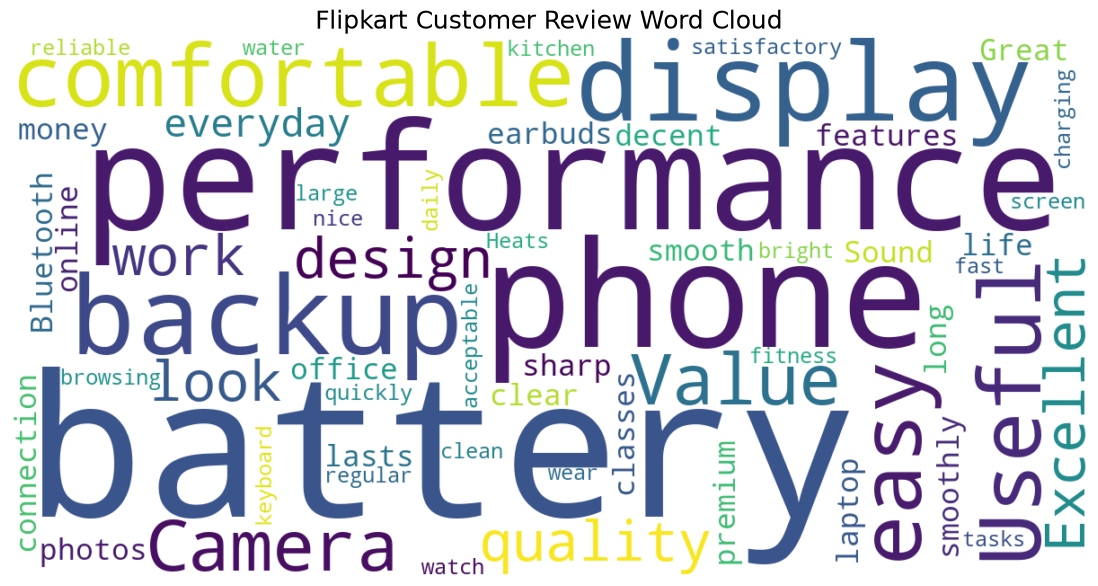

Saved: Exercise4_WordCloud.png


In [7]:
#Generate and display a Word Cloud from Summary
# Combine all customer feedback summaries into one text string.
review_text = " ".join(
    df["Summary"].dropna().astype(str).str.strip()
)

# Remove common English stopwords and generic terms that add little meaning.
stopwords = set(STOPWORDS)
stopwords.update({"good", "product", "use", "using", "one", "also"})

if not review_text.strip():
    raise ValueError("No review text found in the Summary column.")

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    stopwords=stopwords,
    collocations=False,
    min_font_size=10
).generate(review_text)

plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Flipkart Customer Review Word Cloud", fontsize=18)
plt.show()

wordcloud.to_file("Exercise4_WordCloud.png")
print("Saved: Exercise4_WordCloud.png")